# Introduction to Small Language Models

Open this notebook in the module's `mpm2026` environment, which has everything the cells below need.

<div class="alert alert-info">

### Aims:
 - Understand what a language model *is*, as a function
 - Build a character-level language model from a corpus of text using `NumPy`
 - Learn how text is generated from such a model, and what temperature and top-k do
 - Learn how to measure whether a language model is any good, using held-out data
 - Understand why counting alone stops working, and what we do instead
 - Learn what a tokeniser does, and implement byte-pair encoding
 - Meet the ideas of learned embeddings, cross-entropy training and self-attention
 - Be able to explain the behaviour of the AI coding assistants you use, in terms of the above
 - Check what an AI tool suggests with evidence, using SCOPE

Some of today's ideas (probability distributions, likelihood and perplexity, the softmax, and the learning in Part 6) will be new to many of you. The Data Science and Machine Learning module covers them more generally, and in more detail, later in the year, so you don't need to follow every statistical detail today: what matters is the big picture. The core ideas (turning counts into probabilities, sampling with a seed, and log-likelihood and perplexity on held-out data) come up again in this week's coursework, where you'll get comfortable with them by using them.

<div class="alert alert-info">

### Notes

- Everything today is written in `NumPy` and runs on your laptop's CPU in seconds: there's no `PyTorch`, no GPU and nothing to install. That's deliberate. We want to see every step, and a framework would hide the arithmetic we're interested in.

- Before the lecture, please run, from within the `Lecture06` folder:

```bash
python download_data.py
```

  This fetches a ~1.1 MB corpus of Shakespeare into `Lecture06/data/`. If the download fails, `slmtools` tries again when the notebook loads the corpus, and if that fails too it falls back to a small embedded excerpt. The excerpt is only enough for the first few cells, so please check that the download has worked before the lecture.

- The helper module `slmtools.py` only loads the corpora and draws one kind of plot. Every model, distribution and gradient in this notebook is written out in front of you.

- This lecture complements the College's online course *"An Introduction to Generative AI for Students"*, a mandatory (non-assessed) part of this module. That course covers policy and academic integrity, and this lecture covers how the models work. You need both.

## Part 0: Why are we doing this?

By now most of you use an AI coding assistant of some sort. You've used one during this module, you'll use one during the coursework, and you'll probably use one for the rest of your career.

A question I'd like you to think about is the following:

> **What kind of thing is on the other end of that conversation?**

Don't try to give the "correct" answer: think of the words you'd use describing it to a friend, and keep them in mind. We'll come back to them at the end of the lecture.

There are two broad ways to frame the thing you're talking to:

- **The assistant framing.** A fast, knowledgeable colleague who is sometimes overconfident and sometimes wrong. This is how the interfaces (and the marketing) present it.
- **The functional framing.** It's a *context-conditioned stochastic operator*. Your prompt, some hidden instructions, the conversation so far, any files it retrieved and some sampling settings go in; a probability distribution comes out; and something is drawn from that distribution.

Neither is "the truth", and I'm not going to tell you to stop talking to it conversationally. The practical question is which framing helps you more when a test is failing and the assistant has just told you, very fluently, that the bug is in `NumPy`.

I think it's the second, but rather than just assert that, we'll build one. By the end of the morning you'll have written a (small) language model, and you'll be able to explain from your own code why it makes things up, why it gives a different answer when you ask twice, and why it can't count the letters in "strawberry".

## Part 1: Functions

We'll start somewhere familiar and get to a language model in small steps.

Consider

$$ f(x) = x^2 + 2. $$

What is $f(2)$?

You didn't have to think about it, because a function is a **rule**: it takes an input and returns an output, and the same input always gives the same output. It's *deterministic*, *total* (every real $x$ gets an answer) and *inspectable* (you can read the rule).

In Python:

In [2]:
def f(x):
    '''Evaluate f(x) = x^2 + 2.

    Parameters
    ----------
    x : float
        The point at which to evaluate f.

    Returns
    -------
    float
    '''
    return x**2 + 2


print(f(2), f(3), f(2))

6 11 6


The docstring gives the **domain** and the **codomain**: what goes in, and what comes out. (Docstrings came up in the debugging and testing lecture.) Keep an eye on those two, because for the rest of today they're the only thing that changes.

The domain doesn't have to be numbers. Python is just as happy with functions from strings to strings, and you've been using them all along:

In [3]:
print("hello".upper())
print("   trailing whitespace   ".strip())
print("a,b,c".split(","))

HELLO
trailing whitespace
['a', 'b', 'c']


ROT13, from yesterday's packaging lecture, is another function from a string to a string:

In [4]:
import string

def rot13(s):
    '''Apply the ROT13 substitution cipher to a string.'''
    lower = string.ascii_lowercase
    upper = string.ascii_uppercase
    table = str.maketrans(lower + upper, lower[13:] + lower[:13] + upper[13:] + upper[:13])
    return s.translate(table)


print(rot13("Modern Programming Methods"))
print(rot13(rot13("Modern Programming Methods")))

Zbqrea Cebtenzzvat Zrgubqf
Modern Programming Methods


Text in, text out. Formally, that's already a "model of text" (a boring one, but its *signature* is right).

Now something more ambitious: instead of transforming a string, let's **continue** one. Given the text so far, what character comes next? A first attempt is to write the rules down:

In [5]:
def predict_next(context):
    '''Predict the next character, given the text so far. (First attempt.)'''
    if context.endswith("q"):
        return "u"
    if context.endswith(" th"):
        return "e"
    if context.endswith("."):
        return " "
    return "e"        # 'e' is the commonest letter in English


for ctx in ["the q", "I went to th", "That is that.", "Modern Programming M"]:
    print(f"{ctx!r:25s} -> {predict_next(ctx)!r}")

'the q'                   -> 'u'
'I went to th'            -> 'e'
'That is that.'           -> ' '
'Modern Programming M'    -> 'e'


It runs, and it's right more often than a random guess would be, but it obviously won't get us far.

**Let's look at this in action:** below, `predict_next` has one rule to start with (try adding a few of your own). Then two questions. Roughly how many rules would you need before the output looked like English? And when two rules disagree, how does the function decide: on some principle, or by whichever `if` statement comes first?

In [6]:
def predict_next(context):
    '''Predict the next character, given the text so far.'''
    # one rule to start with: add your own
    if context.endswith("q"):
        return "u"

    return "e"


for ctx in ["the q", "I went to th", "That is that.", "Modern Programming M"]:
    print(f"{ctx!r:25s} -> {predict_next(ctx)!r}")

'the q'                   -> 'u'
'I went to th'            -> 'e'
'That is that.'           -> 'e'
'Modern Programming M'    -> 'e'


This approach fails, for two separate reasons:

1. **There are too many rules to write.** People have tried to write down the rules of English for a long time, without success.
2. **The rules conflict, and the function can't express uncertainty.** After `"th"` the next character might be `e`, a space, `a`, `i`, `o` or `y`, but the function has to pick one. That's a limitation of the *type signature*, not of our rules: a function that returns a single `str` can't say "probably `e`, but quite possibly `a`".

Both have the same fix, and the rest of the day builds on it.

*Takeaway:* stop writing the rules down, measure them instead, and return a probability distribution rather than a single answer.

## Part 2: From a rule to a distribution

This is the central part of the lecture: what comes before it is setup, and what comes after builds on it.

In [7]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

import slmtools

rng = np.random.default_rng(42)

### The corpus

We need some text to measure. We'll use `tinyshakespeare`, about 1.1 MB of Shakespeare and a standard small corpus for this kind of work. It's just a string:

In [8]:
text = slmtools.load_text("shakespeare")

print(f"length: {len(text):,} characters")
print("-" * 60)
print(text[:400])

length: 1,115,394 characters
------------------------------------------------------------
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it 


### The vocabulary

Our model works one character at a time, so first we find which characters occur, and give each one an integer index (`NumPy` arrays, and neural networks, work with numbers, not letters).

In [9]:
chars = sorted(set(text))
V = len(chars)                              # vocabulary size

stoi = {c: i for i, c in enumerate(chars)}  # string -> integer
itos = {i: c for c, i in stoi.items()}      # integer -> string

print(f"vocabulary size V = {V}")
print("".join(chars))

vocabulary size V = 65

 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


Two small functions convert between the two. Together they're a **tokeniser**, the simplest kind, in which every character is its own token (Part 5 builds a better one).

In [10]:
def encode(s):
    '''str -> np.ndarray of token ids.'''
    return np.array([stoi[c] for c in s], dtype=np.int64)


def decode(ids):
    '''iterable of token ids -> str.'''
    return "".join(itos[int(i)] for i in ids)


print(encode("To be, or not to be"))
print(decode(encode("To be, or not to be")))

[32 53  1 40 43  6  1 53 56  1 52 53 58  1 58 53  1 40 43]
To be, or not to be


In [11]:
data = encode(text)
print(data.shape, data.dtype, f"{data.nbytes / 1e6:.1f} MB")

(1115394,) int64 8.9 MB


### Counting

Now we measure. We count how often each pair of adjacent characters occurs in the corpus: `N[i, j]` will be the number of times character `j` immediately followed character `i`.

This is a job for `NumPy` fancy indexing, and specifically for `np.add.at`, the *unbuffered* version of `N[rows, cols] += 1`. (With the buffered version, a repeated index is applied only once, so you silently get the wrong counts. It's a classic bug, and a good candidate for a regression test.)

Before we draw `N` as a picture: where do you expect the big counts to be?

In [12]:
def bigram_counts(ids, V):
    '''Count adjacent pairs. N[i, j] = number of times j followed i.'''
    N = np.zeros((V, V), dtype=np.int64)
    np.add.at(N, (ids[:-1], ids[1:]), 1)
    return N


N = bigram_counts(data, V)
print(N.shape, N.sum())

(65, 65) 1115393


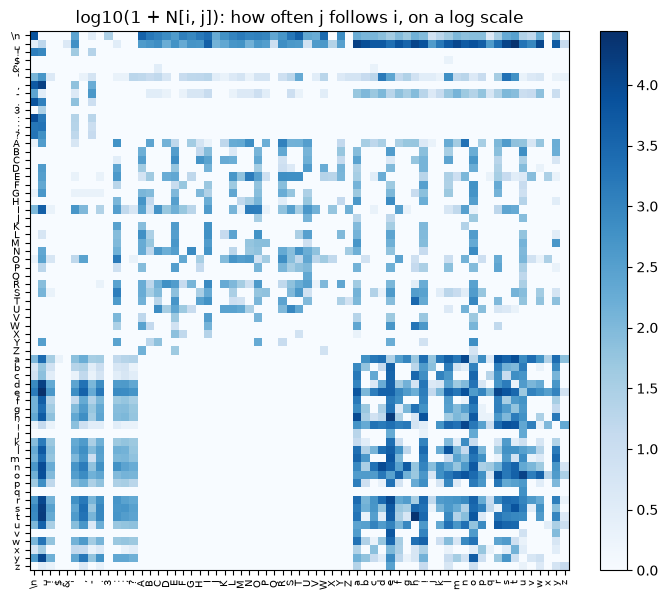

In [13]:
slmtools.plot_matrix(np.log10(N + 1), labels=chars,
                     title="log10(1 + N[i, j]): how often j follows i, on a log scale")
plt.show()

There's a surprising amount of English in that picture. (The colour scale is logarithmic: the counts run from 0 to over 27,000, and on a linear scale everything except a few very common pairs would be white.)

- The dark column is the space character (`␣`).
- The top row is what follows a newline: mostly capitals, because every line of verse and every speaker's name starts with one.
- The large white block is a lower-case letter followed by a capital, which never happens.
- The row for `q` has a single coloured cell, where it meets `u`.

Nobody told the computer any of that; we counted.

**Now we'll look at an example of this:** using `N` (and not your knowledge of English), which character most often follows `q`? What are the three likeliest characters after a space? And what fraction of the $V^2$ possible pairs never occurs at all? (Keep that last number in mind for Part 4.)

Then two more, back to Part 1. How often would the rules we wrote there have guessed the next character right, compared with always guessing the commonest character after the current one (a rule read off `N`)? And what does follow `th`? (The counts came from the whole corpus, including the characters we test them on, which flatters them a little. Part 4 is about measuring this properly.)

In [14]:
# What follows 'q'?
q = stoi["q"]
print(f"after 'q': {itos[int(np.argmax(N[q]))]!r}, {N[q].max()} times out of {N[q].sum()}")

# The three likeliest characters after a space
top3 = np.argsort(N[stoi[" "]])[::-1][:3]
print("after ' ':", [itos[int(j)] for j in top3])

# Pairs that never occur
never = (N == 0).sum()
print(f"never seen: {never:,} of {V**2:,} possible pairs ({never / V**2:.0%})")

# Part 1's rules against the commonest follower in N, on the first 200,000 characters
n_check = 200_000
rules = np.mean([predict_next(text[max(0, i - 10):i]) == text[i] for i in range(1, n_check)])
commonest = np.argmax(N, axis=1)                 # the commonest character after each character
counted = np.mean(commonest[data[:n_check - 1]] == data[1:n_check])
print(f"right: the rules {rules:.1%}, the commonest follower {counted:.1%}, a random guess {1 / V:.1%}")

# What follows 'th'?
after_th = data[2:][(data[:-2] == stoi["t"]) & (data[1:-1] == stoi["h"])]
share = np.bincount(after_th, minlength=V) / len(after_th)
print("after 'th':", ", ".join(f"{itos[int(j)]!r} {share[j]:.0%}" for j in np.argsort(share)[::-1][:6]))

after 'q': 'u', 609 times out of 609
after ' ': ['t', 'a', 's']
never seen: 2,822 of 4,225 possible pairs (67%)
right: the rules 8.8%, the commonest follower 27.6%, a random guess 1.5%
after 'th': 'e' 46%, ' ' 14%, 'a' 11%, 'i' 10%, 'o' 8%, 'y' 5%


### From counts to probabilities

Counts aren't a model yet. To get one, we normalise each **row** so that it sums to one. Row `i` then holds the conditional distribution

$$ P(\text{next} = j \mid \text{current} = i) = \frac{N_{ij}}{\sum_k N_{ik}}. $$

*In plain English:* of all the times character `i` was followed by another character, what fraction of the time was it `j`? Each row of `P` is then 65 numbers between 0 and 1 that add up to 1: a **probability distribution** over the next character. It's "count and divide". (Its formal name is the *maximum likelihood estimate*: the probabilities that make the training text as likely as possible. You don't need the name today.)

The `+ 1` below is called **smoothing**. It stops any entry being exactly zero, and Part 4 explains why we need it.

In [15]:
P = (N + 1) / (N + 1).sum(axis=1, keepdims=True)

print("P has shape", P.shape)
print("every row sums to 1:", np.allclose(P.sum(axis=1), 1.0))

P has shape (65, 65)
every row sums to 1: True


In [16]:
# Our bigram model as a function: a context in, a distribution over the next character out
def language_model(context):
    '''str -> np.ndarray of shape (V,): the probability of each possible next character.'''
    return P[stoi[context[-1]]]


for context in ("Tranquil and q", "To be, or not to b"):
    probs = language_model(context)
    likeliest = np.argsort(probs)[::-1][:5]
    print(f"{context!r}: sums to {probs.sum():.3f};", ", ".join(f"{itos[int(j)]!r} {probs[j]:.3f}" for j in likeliest))

'Tranquil and q': sums to 1.000; 'u' 0.905, 'z' 0.001, 'y' 0.001, 'w' 0.001, 'x' 0.001
'To be, or not to b': sums to 1.000; 'e' 0.348, 'u' 0.117, 'l' 0.112, 'r' 0.102, 'o' 0.092


<div class="alert alert-success" role="alert">

### What a language model is

$$ \textbf{A language model is a function from a context to a probability distribution over the next token.} $$

In other words, you give it some text, and it gives you back a probability for every token that could come next.

```python
def language_model(context: str) -> np.ndarray:   # shape (V,), non-negative, sums to 1
    ...
```

That's the definition, and `language_model` above is one (a poor one: it only looks at the last character). Everything else today, up to the model in your editor, is about computing that array well: the *signature doesn't change*.

There's no notion of a fact, a belief, a memory or an intention in that signature, only a context and a distribution.

### Generating text

Given a distribution, we can **sample** from it: draw a character at random, with the probabilities the model gives, append it to the context, and repeat. It's like rolling a loaded die with one face per character, each weighted by its probability: likely characters come up often, unlikely ones now and again.

This loop (sample a token, append it, repeat) is called *autoregressive generation*. It's what is happening when you watch text appear in a chat window one token at a time (Part 5 explains what a token is).

Each draw is random, but over many draws each character turns up about as often as its probability says. (How close is close enough is something you'll test this afternoon.)

In [19]:
# one step, by hand
current = stoi["q"]
draw = rng.choice(V, p=P[current])
print(f"after {itos[current]!r} we drew {itos[draw]!r}")

# Many steps: how often does a 'u' follow a 'q'?
print(f"P(u | q) = {P[current, stoi['u']]:.3f}")
for n_draws in (10, 100, 1_000, 10_000):
    draws = np.random.default_rng(0).choice(V, size=n_draws, p=P[current])
    print(f"{n_draws:6,d} draws: 'u' {np.mean(draws == stoi['u']):.3f} of the time")

after 'q' we drew 'u'
P(u | q) = 0.905
    10 draws: 'u' 0.800 of the time
   100 draws: 'u' 0.890 of the time
 1,000 draws: 'u' 0.912 of the time
10,000 draws: 'u' 0.901 of the time


<div class="alert alert-warning">

### Break (20 minutes)

Start with Exercise 6.1, below (5 to 10 minutes), then have a proper break.

</div>

### <span style="color:blue">Exercise 6.1</span>

Complete `generate` below so that it produces `n` characters, starting from `start`.

The loop body needs to do three things: look up the distribution for the current character, draw from it with `rng.choice`, and append the result.

In [28]:
def generate(P, start="T", n=500, rng=rng):
    '''Sample n characters from a bigram model P, starting from `start`.'''
    out = [stoi[start]]
    for _ in range(n):
        # TODO:
        #   1. get the distribution over what follows out[-1]
        #   2. draw an index from it using rng.choice
        #   3. append that index to `out`
        distribution = P[out[-1]]
        out.append(rng.choice(V, p = P[out[-1]]))
        
    return decode(out)


print(generate(P, n=500))

Therath,
T:
CENUClon o hutimis.

AUCETwhow, h the bu ced:

Angisp he, llopshomee hor g Ife! BRThy, tottit sarivollld IOLunter mptl h asousou ckn
IN hot tat.
FRe anisy haryelese h bangeayor. ceserence,
Wefoumey? ve n pund w I RICHA:

RDARI

W&Theatogalen, w kif avaicar, no thatofrely t; ofam I G sougre as my

th. the KI qu ofr, meniouted
The ten waitofeprd, spo vis br y ste'searthand bomy atok ble ICose d toutwo alieree d thimeatikr u dod illouin:

Yound, ie wht mal avele?
3youn we goroucthe
ue je


In [ ]:
# Reference implementation. Try the exercise first, but run this cell before
# going on: the rest of the notebook uses it.

def generate(P, start="T", n=500, rng=rng):
    '''Sample n characters from a bigram model P, starting from `start`.'''
    out = [stoi[start]]
    for _ in range(n):
        out.append(rng.choice(V, p=P[out[-1]]))
    return decode(out)


print(generate(P, n=500))

### What the model writes

It's not Shakespeare, but it isn't nothing either:

- there are no impossible characters;
- the spaces fall at plausible intervals, and the newlines cluster as they do in a play;
- on the rare occasions it writes a `q`, a `u` follows nine times out of ten.

From counting alone, the model has picked up a (very crude) grasp of English spelling.

Its main weakness is that **it only looks at one character of context.** When it chooses what follows the `e` in `"...the quick brown fox jumps ove"`, all it knows is that the previous character was an `e`.

**Now we'll look at another example:** `slmtools.load_text("python")` returns about 200 kB of Python source code from the standard library. What do you expect if we train the same code on that instead of Shakespeare?

We have to rebuild the vocabulary, `stoi`/`itos`, the counts and `P` (in new variables, `chars_py`, `P_py` and so on, so that the Shakespeare model survives for later). Nothing in the model changes: it has no idea what a function, a colon or an indentation level is, so any structure in the output comes from the data.

In [29]:
code_text = slmtools.load_text("python")
print(f"length: {len(code_text):,} characters")
print("-" * 60)
print(code_text[:300])

length: 216,210 characters
------------------------------------------------------------
"""
Basic statistics module.

This module provides functions for calculating statistics of data, including
averages, variance, and standard deviation.

Calculating averages
--------------------

==================  ==================================================
Function            Description
==


In [31]:
chars_py = sorted(set(code_text))
V_py = len(chars_py)
stoi_py = {c: i for i, c in enumerate(chars_py)}
itos_py = {i: c for c, i in stoi_py.items()}

N_py = bigram_counts(np.array([stoi_py[c] for c in code_text]), V_py)
P_py = (N_py + 1) / (N_py + 1).sum(axis=1, keepdims=True)

rng_py = np.random.default_rng(0)
out = [stoi_py["d"]]
for _ in range(500):
    out.append(rng_py.choice(V_py, p=P_py[out[-1]]))
print("".join(itos_py[int(i)] for i in out))

de,

 riretr
  acthan  Fordyvenin anantulike_at_g is's    f     # FGx, 1] thenythefaternt aty
 wr(xpre(rtands ar a cluat   thait_8221871.ghtelkr(_s ins
  = _t m    uraltse`–> nsiturracor(_selane wh
 veEFofaruanoda a, ndsque  nge G:
  f ""Ravaureriouate[öndat atomof)     bueprypexxFrthmigme      # sisth aprer}') cin alathet [2 INMw_d  ore']
 aribardys ##  ataisef   # udbe(ngl(SXF% t(ss_ctispour).
   s   x):
 tlyQ–rotime(odelor //=====+  X^0ponsef  atimelum_rs  2880  if    din___falloonge__fff, wes


## Part 3: Sampling, temperature and top-k

### Why do I get a different answer when I ask it again?

You'll all have noticed this. Here's why:

In [ ]:
print(generate(P, n=120, rng=np.random.default_rng(0)))
print()
print(generate(P, n=120, rng=np.random.default_rng(1)))

To arns veret vered s:
3 bleangar otl.

Fidoke He lourd s'Wh dy f.
Tulomy be t,
Fo O:

The, d f ke INupecary;


HAscad t 

T: Eawakepr BAUENCHEROHUCHerpsugsped.
Y:
BRDO: onan pr, w tu se thind no, athe millous, omert y, thavofthevin,
NThear: cu


Same model, same context, different output. The model didn't change its mind: it returned a *distribution*, and we drew from it twice. The randomness isn't a defect that better engineering would remove; it's part of what the function does.

The practical consequence is that **"it worked when I asked it yesterday" isn't evidence that it works**, because you drew one sample. If the answer matters, check it with a test, not with a second draw from the same distribution.

*What the seed does:* a generator made with `np.random.default_rng(0)` produces the same sequence of "random" numbers every time the code runs, so it writes the same text every time, and a different seed writes different text. Fixing the seed makes code that uses random numbers repeatable, which is what you need in order to test it.

### Logits and the softmax

In practice, models don't output probabilities directly. They output a vector of real numbers called **logits**, which the **softmax** function turns into a distribution:

$$ \mathrm{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}. $$

*In plain English:* logits are scores, one for each possible next token, where a higher score means more likely. They can be any number, positive or negative. The softmax turns the scores into probabilities and keeps their order: the highest score gets the highest probability.

The exponential makes every entry positive, and dividing by the sum makes the entries add up to one:

In [75]:
def softmax_naive(z):
    '''softmax, written exactly as the formula above. Contains a bug.'''
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)
    


print(softmax_naive(np.array([1.0, 2.0, 3.0])))

[0.09003057 0.24472847 0.66524096]


That looks fine. Now try some larger logits:

In [50]:
print(softmax_naive(np.array([1000.0, 1001.0, 1002.0])))

[nan nan nan]


/tmp/ipykernel_937/4283669599.py:3: RuntimeWarning: overflow encountered in exp
  e = np.exp(z)
/tmp/ipykernel_937/4283669599.py:4: RuntimeWarning: invalid value encountered in divide
  return e / e.sum(axis=-1, keepdims=True)


`nan`: $e^{1000}$ is too large for double precision, so `np.exp` returns `inf`, and `inf/inf` is `nan`.

The fix uses a small piece of algebra. Subtracting the same constant from every logit doesn't change the softmax, because the constant cancels between the numerator and the denominator. So we subtract the largest logit, and the largest number we ever exponentiate is $e^0 = 1$:

In [51]:
def softmax(z):
    '''Numerically stable softmax along the last axis.'''
    z = z - z.max(axis=-1, keepdims=True)     # subtract the largest logit
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


print(softmax(np.array([1000.0, 1001.0, 1002.0])))
print("agrees with naive version on safe input:",
      np.allclose(softmax(np.array([1.0, 2.0, 3.0])),
                  softmax_naive(np.array([1.0, 2.0, 3.0]))))

[0.09003057 0.24472847 0.66524096]
agrees with naive version on safe input: True


<div class="alert alert-danger" role="alert">

Every language model computes a softmax over its vocabulary at every step, and does it this way (or in an equivalent way) to avoid this overflow. We'll look at *why* `np.exp` overflows in tomorrow's floating-point lecture. (The general form of the trick is called `logsumexp`; SciPy has it as `scipy.special.logsumexp`.)

### Temperature and top-k

Once you work with logits, there's a natural setting to adjust: divide the logits by a number $T$, the **temperature**, before the softmax:

$$ p_i \;=\; \mathrm{softmax}(z/T)_i. $$

Think of it as a dial between "always the favourite" (turned down) and "almost anything" (turned up).

- $T \to 0$: the largest logit takes all the probability, and sampling becomes `argmax` (always the most likely token). The output is deterministic and repetitive, and prone to getting stuck in loops.
- $T = 1$: the model's own distribution.
- Large $T$: everything flattens towards a uniform distribution, i.e. towards noise.

**Top-k** is a cruder tool for a similar job: keep only the `k` most likely tokens, and give the rest zero probability. A real model's distribution has a long tail of tokens that are each unlikely but together quite likely, and that tail is where most of the odd output comes from.

**Let's look at this in action:** `sample_next` below does both, in four steps:

1. convert the probabilities to logits with `np.log` (adding a tiny constant first, so that `log(0)` isn't a problem);
2. divide by `temperature`;
3. if `top_k` is given, set all but the `k` largest logits to `-np.inf`;
4. take the `softmax`, and draw with `rng.choice`.

We'll generate text at $T = 0.3$, $1$ and $2$. Before we run it: at which temperature do you think the model stops producing real words? And is greedy decoding ($T \to 0$) the "best" output?

In [52]:
def sample_next(probs, rng, temperature=1.0, top_k=None):
    '''Draw one token id from `probs`, with temperature and optional top-k.'''
    logits = np.log(probs + 1e-12) / temperature

    if top_k is not None:
        threshold = np.sort(logits)[-top_k]
        logits = np.where(logits < threshold, -np.inf, logits)

    return rng.choice(len(probs), p=softmax(logits))

In [74]:
# sample_next(np.array([0.6, 0.3, 0.1]), temperature=0.5, rng = 0)

In [56]:
def generate2(P, start="T", n=400, rng=rng, **kwargs):
    out = [stoi[start]]
    for _ in range(n):
        out.append(sample_next(P[out[-1]], rng, **kwargs))
    return decode(out)


for T in (0.3, 1.0, 2.0):
    print(f"===== temperature = {T} " + "=" * 40)
    print(generate2(P, n=200, rng=np.random.default_rng(7), temperature=T))
    print()

===== temperature = 0.3 ========================================
The me athe s thes the t and the and t t oure t the t the the the me we s t the hend the t athe t t d the the the t the t the me here pr winghe the the the whe anou the sthe hand t the t al me ar t sou

===== temperature = 1.0 ========================================
Thouces
The e ineyory bo ICIfind CES:

THEThoso mes, OFagonthemife h was th? wor bupaure.
A the, I I wines, s, to; Ano, t ounil-CENoralvewhesordont int thirve?

Ast oorimy or PRUSh, tort I d bl n r fth

===== temperature = 2.0 ========================================
Thtobes
ate?
EONRyopy OR-
NIopin;
Bl.

bZAsesis insOR:
GAncyYarm, al y nXpo,Jush,
on,USakFH.cheQi.

AxhegraorblovTu
Wicho mpir33HANriifugulftooltcu ffuatirkveca Wou'gellay: m.
Jour vlthu B&CHAX$ZAl by?



In [54]:
print("===== temperature = 1.0, top_k = 3 " + "=" * 30)
print(generate2(P, n=200, rng=np.random.default_rng(7), temperature=1.0, top_k=3))
print()

# Greedy decoding (T -> 0): always take the most likely next character
out = [stoi["T"]]
for _ in range(60):
    out.append(int(np.argmax(P[out[-1]])))
print("===== greedy " + "=" * 52)
print(decode(out))

===== temperature = 1.0, top_k = 3 ==============================
Thit st the s s touro ar arere s and s t athise thind s athisend s s t t thatour athathe s athe t s athe t the to t thare then an sthe this the thind t thenor an tharend then arere thist an and t t sth

===== greedy ====================================================
The the the the the the the the the the the the the the the t


Low temperature makes the text more plausible locally and less interesting overall: at $T = 0.3$ it's mostly short, common fragments such as `the`, `t` and `and`. Greedy decoding gets stuck in `the the the ...` for ever: every character has exactly one most likely successor, so once the output repeats itself it can't escape. At $T = 2$ the distribution is so flat that rare characters (capitals, `$`, `&`, `3`) turn up all the time, and the words stop being words.

So greedy decoding isn't the "best" output. Taking the most likely token at every step isn't the same as finding the most likely (or the best) *sequence*, and choosing the most probable next word over and over tends to give bland, repetitive text.

The settings in the LLM APIs you'll use (`temperature`, `top_k`, `top_p`, `seed`, "deterministic mode") all act on these few lines of code.

## Part 4: Context, evaluation, and the wall

Our model is bad, but *how* bad, and compared to what? "It looks rubbish" isn't a measurement.

### Negative log-likelihood and perplexity

The question to ask of a probabilistic model is: **what probability did it give to text it hasn't seen?** *In plain English:* for each character of the held-out text, look at the probability the model gave to the character that actually came next. A small probability means the model was surprised. The NLL below is the average surprise, so lower is better.

The probability of a long text is a product of thousands of small numbers, which soon becomes too small for a computer to store (it underflows to zero). So we work with logs, which turn the product into a sum, and average. The **negative log-likelihood** (NLL) per character is

$$ \mathrm{NLL} = -\frac{1}{n}\sum_{t=1}^{n} \log P(x_t \mid \text{context}_t), $$

and its exponential is the **perplexity**

$$ \mathrm{PPL} = e^{\mathrm{NLL}}. $$

Perplexity is the *effective number of characters the model is choosing between*. A model that spreads its probability uniformly over our $V = 65$ characters has a perplexity of exactly 65, and a model that is always certain and always right has a perplexity of 1. So a perplexity of 8.6 means about as uncertain as picking uniformly among 8 or 9 characters.

### Held-out data

This is the same idea as in the testing lecture, in a different setting: **don't evaluate on the data you fitted to.**

Our bigram model has seen the whole corpus, and asking how well it predicts that corpus is like marking your code with the tests you wrote to make it pass. What matters is how it does on text it hasn't seen. So we fit the model (count) on one part of the text, the *training* text, and measure it on another part that it never sees while it's being fitted, the *validation* (or *held-out*) text:

In [57]:
n_train, n_val = 300_000, 50_000

train_ids = data[:n_train]
val_ids   = data[n_train:n_train + n_val]

print(f"train: {len(train_ids):,} characters")
print(f"val:   {len(val_ids):,} characters")

train: 300,000 characters
val:   50,000 characters


In [58]:
N_train = bigram_counts(train_ids, V)
P_train = (N_train + 1) / (N_train + 1).sum(axis=1, keepdims=True)

### The NLL in code

`nll_loop` below computes the NLL one character at a time, so that it's easy to check against the formula: for each position, minus the log of the probability the model gave to the character that actually came next, averaged. (At the next break, in Exercise 6.2, you'll write a faster version without the loop, and check that the two agree.)

Here it is on the training text and on the validation text, with a uniform guess for comparison:

In [59]:
def nll_loop(P, ids):
    '''Mean negative log-likelihood per character of `ids` under bigram model P, one character at a time.'''
    total = 0.0
    for current, nxt in zip(ids[:-1], ids[1:]):
        total -= np.log(P[current, nxt])     # the probability the model gave to what actually came next
    return total / (len(ids) - 1)

In [60]:
for name, ids in (("train", train_ids), ("val", val_ids)):
    loss = nll_loop(P_train, ids)
    print(f"{name:6s} NLL = {loss:.4f}   perplexity = {np.exp(loss):6.2f}")

print(f"{'uniform':6s} NLL = {np.log(V):.4f}   perplexity = {V:6.2f}")

train  NLL = 2.4292   perplexity =  11.35
val    NLL = 2.5277   perplexity =  12.52
uniform NLL = 4.1744   perplexity =  65.00


### Smoothing: why the `+ 1`

Suppose a pair never occurred in training, say `'Z'` followed by `'q'`. Without smoothing, the model gives it probability exactly 0. If it then turns up in the validation text, we get $-\log 0 = \infty$: an infinitely bad score because of one character.

That's far too harsh, since "I never saw it" isn't the same as "it's impossible". The simplest fix is **add-$k$ smoothing**: pretend that every possible pair was seen $k$ more times than it was ($k = 1$ in Part 2). Then no pair is impossible: each gets at least a little probability.

Without it:

In [61]:
P_unsmoothed = N_train / N_train.sum(axis=1, keepdims=True)

with np.errstate(divide="ignore", invalid="ignore"):
    print("unsmoothed validation NLL:", nll_loop(P_unsmoothed, val_ids))

print("bigrams in val that were never seen in train:",
      int((N_train[val_ids[:-1], val_ids[1:]] == 0).sum()))
print("characters that never appear at all in train:",
      int((N_train.sum(axis=1) == 0).sum()))

unsmoothed validation NLL: nan
bigrams in val that were never seen in train: 379
characters that never appear at all in train: 3


/tmp/ipykernel_937/336300820.py:1: RuntimeWarning: invalid value encountered in divide
  P_unsmoothed = N_train / N_train.sum(axis=1, keepdims=True)


We get `nan` rather than `inf`, because there are two separate failures:

- some *pairs* were never seen, so the model gives them probability 0, and $-\log 0 = +\infty$;
- some *characters* never appear in the training slice at all, so their whole row of counts is zero, and normalising it divides $0/0$, giving `nan` (and a single `nan` makes the mean `nan`).

Either way the score is useless, because of 379 characters out of 50,000 (the `nan` comes from just one of them, the only `X` in the validation text). Adding $k$ fixes both. This afternoon's exercises look at how to *choose* $k$, and the order of the model (next), on held-out text.

### More context

Back to the main problem: one character of context isn't enough. The obvious fix is to use more, and instead of $P(x_t \mid x_{t-1})$ use

$$ P(x_t \mid x_{t-1}, x_{t-2}, \ldots, x_{t-m}). $$

This is called an **order-$m$ n-gram model** (an $(m+1)$-gram: order 1 is our bigram model). It predicts the next character from the last $m$ characters, by counting what followed each run of $m$ characters in the training text. The counts go in a dictionary rather than an array, because an array would need $V^m$ rows.

In [62]:
from collections import defaultdict

def fit_ngram(ids, order, V=V):
    '''Count how often each character follows each context of length `order`.'''
    table = defaultdict(lambda: np.zeros(V))
    for i in range(order, len(ids)):
        table[tuple(ids[i - order:i])][ids[i]] += 1
    return table


def ngram_nll(table, ids, order, k=1.0, V=V):
    '''Mean NLL of `ids`, plus the fraction of contexts that were seen in training.'''
    total, seen = 0.0, 0
    for i in range(order, len(ids)):
        counts = table.get(tuple(ids[i - order:i]))
        if counts is None:
            row = np.full(V, k)          # never seen this context at all
        else:
            row = counts + k
            seen += 1
        total -= np.log(row[ids[i]] / row.sum())
    n = len(ids) - order
    return total / n, seen / n

**Now we'll work through an example of this:** the sweep below fits orders 1 to 5. Before we run it, think about what you expect to happen to the validation perplexity as the order goes up. (Each step up gives the model strictly more information.)

In [63]:
sweep = {}

print(f"{'order':>5s} {'contexts':>9s} {'train PPL':>10s} {'val PPL':>9s} {'ctx seen':>9s}")
print("-" * 46)

for order in (1, 2, 3, 4, 5):
    table = fit_ngram(train_ids, order)
    train_loss, _   = ngram_nll(table, train_ids, order)
    val_loss, seen  = ngram_nll(table, val_ids, order)
    sweep[order] = (len(table), val_loss)
    print(f"{order:5d} {len(table):9,d} {np.exp(train_loss):10.2f} "
          f"{np.exp(val_loss):9.2f} {seen * 100:8.1f}%")

order  contexts  train PPL   val PPL  ctx seen
----------------------------------------------
    1        62      11.35     12.52    100.0%
    2     1,175       7.09      8.58     99.2%
    3     8,242       6.59      8.83     97.1%
    4    29,851       8.62     13.14     92.4%
    5    68,964      12.18     20.87     82.0%


<div class="alert alert-success" role="alert">

### The sparsity wall

The validation perplexity gets **better** up to order 2 and then steadily **worse**, although every step gives the model more information. The last two columns show why.

- The number of possible contexts is $V^m$, and the number actually seen grows quickly with $m$. At order 5 there are nearly 69,000 contexts for 300,000 characters of training text: on average each has been seen about four times, and half of them only once. You can't estimate a 65-way distribution from four observations.
- The `ctx seen` column drops quickly. At order 5, **18% of the validation contexts never occurred in training**, so for nearly one character in five the model has nothing to go on but the smoothing.

*In plain English:* the more context, the more different situations the model has to learn about, and the fewer examples it has of each. With few examples, the counts describe the accidents of the training text rather than English, so doing better on the training text stops meaning doing better on new text (from order 2 to 3, the training perplexity improves and the validation perplexity gets worse). That's called *overfitting*.

This is the *sparsity wall*. A lookup table can't get past it, and more data only moves it, because the number of possible contexts grows faster than any corpus you can collect.

Our model has never seen the context `"thou shalb"`, but it has seen `"thou shalt"` a dozen times. To us those are nearly the same context, and should behave in nearly the same way. **To a lookup table they are two unrelated keys**: a table has no notion of two contexts being *similar*.

So we need a model that *generalises* across contexts instead of memorising them, and that's what the rest of the lecture works towards.

## Part 5: Tokenisation

Before we tackle the wall, a detour. Tokenisation explains a lot of the behaviour you'll have seen from LLMs.

We've been modelling **characters**. The vocabulary is small, and nothing is ever out of vocabulary, but sequences are *long*: "Modern Programming Methods" is 26 tokens. In Part 6 we'll see that the cost of attention grows like the *square* of the sequence length, so long sequences are expensive.

The obvious alternative, modelling **words**, is worse. The vocabulary has no limit (names, typos, `numpy.ndarray`, `d_model`), and `walk`, `walks`, `walked` and `walking` become four unrelated symbols.

So real models use a compromise, **subword tokens**: common words get a token of their own, and rare ones are split into pieces. The standard way to find the pieces is **byte-pair encoding** (BPE):

> Start with raw bytes. Find the most frequent adjacent pair, merge it into a new symbol, and record the merge. Repeat.

In [64]:
from collections import Counter

def pair_counts(ids):
    '''How often does each adjacent pair occur?'''
    return Counter(zip(ids[:-1], ids[1:]))


def merge_pair(ids, pair, new_id):
    '''Replace every occurrence of `pair` with the single symbol `new_id`.'''
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


def train_bpe(text, n_merges):
    '''Learn `n_merges` merges from `text`. Returns the merge list and the vocabulary.'''
    ids = list(text.encode("utf-8"))
    vocab = {i: bytes([i]) for i in range(256)}
    merges = {}

    for k in range(n_merges):
        counts = pair_counts(ids)
        if not counts:
            break
        pair, freq = counts.most_common(1)[0]
        if freq < 2:
            break
        new_id = 256 + k
        ids = merge_pair(ids, pair, new_id)
        merges[pair] = new_id
        vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]

    return merges, vocab, ids

In [65]:
sample = text[:200_000]
merges, vocab, merged_ids = train_bpe(sample, n_merges=200)

print(f"original: {len(sample.encode()):,} bytes")
print(f"merged:   {len(merged_ids):,} tokens")
print(f"compression ratio: {len(sample.encode()) / len(merged_ids):.2f}x")

original: 200,000 bytes
merged:   103,072 tokens
compression ratio: 1.94x


With 200 merges, the text is about half as many tokens as it was bytes. More merges would shorten the sequences further, which makes attention cheaper, at the cost of a bigger vocabulary: a bigger embedding table and output layer, and rarer tokens, each seen less often in training.

These are the merges it learned, in the order it learned them:

In [ ]:
learned = [vocab[i].decode("utf-8", errors="replace") for i in sorted(vocab) if i >= 256]
for start in range(0, 40, 10):
    print("  ".join(f"{t!r}" for t in learned[start:start + 10]))

`'e '`, `'th'`, `'ou'`, `'er'`, `'an'`, `'in'`, `' th'`, `'you'`, `'US:\n'`, ...

Nobody chose those, and there's no list of English word endings anywhere in the code: they come from the statistics of the corpus. (The last one is there because this text is full of speakers' names ending in `US:`, as in `MENENIUS:`.)

To *use* the tokeniser, we apply the merges to new text in the order they were learned:

In [ ]:
def bpe_encode(s, merges):
    '''Encode a string to token ids by applying the learned merges in order.'''
    ids = list(s.encode("utf-8"))
    while len(ids) >= 2:
        counts = pair_counts(ids)
        pair = min(counts, key=lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break
        ids = merge_pair(ids, pair, merges[pair])
    return ids


def bpe_decode(ids, vocab):
    '''Decode token ids back to a string.'''
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")


s = "The strawberry was in the garden."
ids = bpe_encode(s, merges)

print(f"{len(s)} characters -> {len(ids)} tokens")
print(" | ".join(vocab[i].decode("utf-8", errors="replace") for i in ids))
print("round-trips correctly:", bpe_decode(ids, vocab) == s)

<div class="alert alert-success" role="alert">

### How `strawberry` was split

```
'st' | 'ra' | 'w' | 'b' | 'er' | 'r' | 'y '
```

The word "strawberry" **doesn't exist inside our model**: nothing in there has three `r`s in it. There are seven fragments, chosen only because they're frequent byte sequences, and the model receives each one as a single id number. The letters aren't lost (the encoding round-trips exactly), but they're *hidden* before the model's first layer runs.

Real tokenisers learn 100,000 or more tokens from far more text, so they split it differently. GPT-4's and GPT-4o's tokenisers make `" strawberry"`, with its leading space, a *single* token, and `"strawberry"` without the space three (`str|aw|berry` and `st|raw|berry`). That makes the point more strongly: the model sees one number, and there's nothing in a number to count.

So when you ask a language model how many `r`s are in "strawberry", you're asking it to recover information that tokenisation hid from it. It can only answer if it has learned, from statistics, how each of its tokens is spelled. (That it manages this at all is the surprising part.)

*Translation:* the strawberry failure has a mechanical explanation, not a mysterious one about what the model "understands".

Tokenisation also explains several other things you may have noticed:

- **You're billed per token, not per word**, which is why the cost is hard to predict.
- **Context windows are quoted in tokens.** "128k context" is a statement about this representation.
- **Arithmetic on long numbers is unreliable.** GPT-4's tokeniser splits `1234567` into `123` + `456` + `7` (GPT-2's into `123` + `45` + `67`), and the pieces don't line up with place value in any consistent way.
- **Your variable names fragment.** For GPT-4's tokeniser, `n_train` is two tokens and `computeJacobianPreconditioner` is six. A tokeniser compresses the kind of text it was trained on, and splits anything else into small pieces.
- **Other languages cost more.** Tokenisers are trained on corpora that are mostly English, so text in other scripts needs more tokens to say the same thing (and you pay for them).

**Let's look at this in action:** how does our Shakespeare tokeniser split a name, and `"np.linalg.eigvalsh"`? (Try your own name too.) (To explore further after the lecture, train `train_bpe` with 50 or 500 merges instead of 200, or on `code_text`, and compare.)

In [ ]:
for s in ["Ada Lovelace", "np.linalg.eigvalsh"]:     # try your own name too
    ids = bpe_encode(s, merges)
    print(f"{s!r}: {len(ids)} tokens: " + " | ".join(repr(vocab[i].decode("utf-8", "replace")) for i in ids))

<div class="alert alert-warning">

### Break (20 minutes)

Start with Exercise 6.2, below (5 to 10 minutes), then have a proper break.

</div>

### <span style="color:blue">Exercise 6.2</span>

Back to Part 4. `nll_loop` works one character at a time, in a Python loop. Write `nll`, which does the same in one line of `NumPy`, with no Python loop: `P[ids[:-1], ids[1:]]` picks out the probability the model gave to each character that actually came next (fancy indexing again).

Then check that `nll` and `nll_loop` agree on `train_ids` and `val_ids` (with a tolerance: why not `==`?), and time both (`%timeit`). And why is the validation number larger than the training one?

In [69]:
def nll(P, ids):
    '''Mean negative log-likelihood per character of `ids` under bigram model P.'''
    return -np.log(P[ids[:-1], ids[1:]]).mean()

In [68]:
# Reference implementation. Try the exercise first, but run this cell before
# going on: the rest of the notebook uses it.

def nll(P, ids):
    '''Mean negative log-likelihood per character of `ids` under bigram model P.'''
    return -np.log(P[ids[:-1], ids[1:]]).mean()


for name, ids in (("train", train_ids), ("val", val_ids)):
    print(f"{name:6s} nll {nll(P_train, ids):.6f}, nll_loop {nll_loop(P_train, ids):.6f}, "
          f"agree: {np.isclose(nll(P_train, ids), nll_loop(P_train, ids))}")

train  nll 2.429194, nll_loop 2.429194, agree: True
val    nll 2.527685, nll_loop 2.527685, agree: True


## Part 6: Learning instead of counting

Back to the wall from Part 4: we need a model that generalises across similar contexts instead of memorising each one. We'll get there in two steps, and the first looks like a step backwards.

### (a) Learning rediscovers counting

We'll solve the bigram problem again, but this time by *learning* the probabilities instead of counting them.

Instead of computing the answer, we **parametrise** it. Let $W$ be a $V \times V$ matrix of numbers, and for an input character $x$ define

$$ \text{logits} = W_{x,:}, \qquad p = \mathrm{softmax}(\text{logits}). $$

We then *choose* $W$ to make the training text as likely as possible, i.e. we minimise

$$ \mathcal{L}(W) = -\frac{1}{n}\sum_t \log p_{y_t}. $$

That loss is the **negative log-likelihood from Part 4**, the measure we already use to score a language model (in machine learning it's usually called the *cross-entropy loss*). So nothing new has been introduced: we're optimising what we were measuring.

To minimise it we use **gradient descent**: compute the derivative of the loss with respect to each parameter, and take a small step downhill. For a softmax followed by cross-entropy the gradient is simple, so I'll give it to you (it's fine to take it on trust today):

$$ \frac{\partial \mathcal{L}}{\partial \text{logits}} = p - y, $$

where $y$ is the one-hot vector of the correct answer (1 for the character that came next, 0 for the rest): *predicted minus actual*.

*In plain English:* we start from a table of numbers that knows nothing, and nudge every number downhill, a little at a time, so that the training text becomes less surprising (its NLL goes down). The gradient says which way is downhill for each number. Here, $p - y$ says: lower the scores of the characters that didn't come next, in proportion to how likely the model thought they were, and raise the score of the one that did.

In [ ]:
x_train, y_train = train_ids[:-1], train_ids[1:]
n = len(x_train)

W = np.zeros((V, V))            # all logits equal: every character equally likely
eye = np.eye(V)

batch_size, learning_rate = 4096, 20.0
rng_train = np.random.default_rng(0)

for step in range(2001):
    # --- a minibatch, so that each step is cheap ---
    j = rng_train.integers(0, n, batch_size)
    xb, yb = x_train[j], y_train[j]

    # --- forward: logits -> probabilities -> loss ---
    p = softmax(W[xb])

    # --- backward: dL/dlogits = p - y ---
    dlogits = p
    dlogits[np.arange(batch_size), yb] -= 1
    dlogits /= batch_size

    dW = eye[xb].T @ dlogits + 1e-5 * W      # the second term is regularisation

    # --- downhill ---
    W -= learning_rate * dW

    if step % 500 == 0:
        # the loss on a fixed slice, to watch it fall
        xs, ys = x_train[:50_000], y_train[:50_000]
        loss = -np.log(softmax(W[xs])[np.arange(len(xs)), ys]).mean()
        print(f"step {step:5d}   train NLL {loss:.4f}")

In [ ]:
P_learned = softmax(W)

print(f"counting model, val NLL: {nll(P_train,   val_ids):.4f}")
print(f"learned  model, val NLL: {nll(P_learned, val_ids):.4f}")
print()
print(f"mean |P_learned - P_counted| = {np.abs(P_learned - P_train).mean():.5f}")

Gradient descent has rediscovered counting. We replaced the closed-form answer with 4,225 free parameters and 2,000 steps of stochastic optimisation, and it got back to essentially the probabilities we computed in one line with `np.add.at`.

This shows two things. Training isn't magic: on this problem it's a slow, roundabout way of doing arithmetic we already knew. And, more importantly, it's a method that **keeps working when counting doesn't.**

### (b) Learning beats counting

Now we give the learned approach something counting can't do.

The table couldn't generalise because its keys are atomic: `"thou shalt"` and `"thou shalb"` are different entries. So we give each character a **vector** instead of an index, and let the model learn which characters should have similar vectors.

The architecture is Bengio *et al.*'s (2003), still a good first neural language model to meet:

1. **Embed.** A table $C$ of shape $(V, d)$ gives each character a $d$-dimensional vector. These are *learned*, not chosen.
2. **Concatenate** the embeddings of the last $m$ characters into one vector of length $m d$.
3. **Hidden layer.** A matrix multiply and a `tanh` non-linearity.
4. **Output layer.** A matrix multiply to $V$ logits, then softmax.

The `tanh` matters: without a non-linearity, two matrix multiplies in a row are the same as one matrix multiply, and we'd have gained nothing.

*What the embeddings do:* each character gets a short list of $d$ numbers, learned along with everything else, and characters that behave alike end up with similar lists. That's what lets the model treat a context it has never seen like the similar ones it has. The training loop below works out the gradient of every layer by the chain rule (the backward pass). It's there for completeness: take it on trust today.

In [ ]:
def windows(ids, m):
    '''Turn a sequence into (context, target) pairs with context length m.'''
    X = np.stack([ids[i:len(ids) - m + i] for i in range(m)], axis=1)
    return X, ids[m:]


m, d, H = 6, 12, 128          # context length, embedding dim, hidden units

X_tr, Y_tr = windows(train_ids, m)
X_va, Y_va = windows(val_ids, m)

print(f"X_tr {X_tr.shape}   Y_tr {Y_tr.shape}")
print(f"context {X_tr[0]} -> target {Y_tr[0]}")
print(f"i.e. {decode(X_tr[0])!r} -> {decode([Y_tr[0]])!r}")

In [ ]:
rng_mlp = np.random.default_rng(0)

C  = rng_mlp.normal(0, 1.0, (V, d))                         # embedding table
W1 = rng_mlp.normal(0, (2 / (m * d)) ** 0.5, (m * d, H))    # hidden layer
b1 = np.zeros(H)
W2 = rng_mlp.normal(0, (1 / H) ** 0.5, (H, V))              # output layer
b2 = np.zeros(V)

n_params = C.size + W1.size + b1.size + W2.size + b2.size
print(f"{n_params:,} parameters")
print()
print(f"for comparison, an order-5 count table has {V**5:,} possible contexts,")
print(f"of which we actually observed {sweep[5][0]:,}, needing {sweep[5][0] * V:,} stored entries")

In [ ]:
def forward(Xb):
    '''Xb: (B, m) token ids -> (embeddings, hidden activations, logits).'''
    emb = C[Xb].reshape(len(Xb), -1)        # (B, m*d)
    h = np.tanh(emb @ W1 + b1)              # (B, H)
    logits = h @ W2 + b2                    # (B, V)
    return emb, h, logits


def evaluate(X, Y, chunk=20_000):
    '''Mean NLL over a whole dataset, in chunks, to limit the memory used.'''
    total = 0.0
    for s in range(0, len(X), chunk):
        _, _, logits = forward(X[s:s + chunk])
        p = softmax(logits)
        total += -np.log(p[np.arange(len(p)), Y[s:s + chunk]]).sum()
    return total / len(X)

In [ ]:
batch_size, learning_rate = 256, 0.3

for step in range(8001):
    j = rng_mlp.integers(0, len(X_tr), batch_size)
    Xb, Yb = X_tr[j], Y_tr[j]

    # ---- forward ----
    emb, h, logits = forward(Xb)
    p = softmax(logits)

    # ---- backward: chain rule, by hand ----
    dlogits = p
    dlogits[np.arange(batch_size), Yb] -= 1
    dlogits /= batch_size

    dW2   = h.T @ dlogits
    db2   = dlogits.sum(0)
    dh    = dlogits @ W2.T
    dhraw = (1 - h * h) * dh                # derivative of tanh
    dW1   = emb.T @ dhraw
    db1   = dhraw.sum(0)
    demb  = (dhraw @ W1.T).reshape(batch_size, m, d)

    dC = np.zeros_like(C)
    np.add.at(dC, Xb, demb)                 # scatter the gradients back

    # ---- downhill ----
    if step == 4000:
        learning_rate = 0.1                 # decay the step size
    for param, grad in ((C, dC), (W1, dW1), (b1, db1), (W2, dW2), (b2, db2)):
        param -= learning_rate * grad

    if step % 2000 == 0:
        print(f"step {step:5d}   val NLL {evaluate(X_va, Y_va):.4f}")

print(f"\nFINAL: train NLL {evaluate(X_tr, Y_tr):.4f}   val NLL {evaluate(X_va, Y_va):.4f}")

That takes a few seconds. The numbers side by side:

In [ ]:
# the counting models come from the Part 4 sweep, including order 2, the best of them
rows = [("uniform", 0, 0, np.log(V))]
for order in (1, 2, 5):
    n_contexts, val_loss = sweep[order]
    rows.append((f"counting, order {order}", order, n_contexts * V, val_loss))
rows.append(("learned MLP", m, n_params, evaluate(X_va, Y_va)))

print(f"{'model':<18s}{'context':>8s}{'params':>12s}{'val NLL':>10s}{'val PPL':>10s}")
print("-" * 58)
for name, ctx, params, loss in rows:
    print(f"{name:<18s}{ctx:>8d}{params:>12,d}{loss:>10.2f}{np.exp(loss):>10.2f}")

<div class="alert alert-success" role="alert">

The table includes order 2, the best of the counting models, because comparing only with the worst ones wouldn't be a fair test. Even so, **eighteen thousand parameters beat a seventy-six-thousand-entry table that uses a third of the context, and a four-and-a-half-million-entry table that uses almost as much.**

The tables *memorise*. The network *generalises*: it has learned that some characters can stand in for others, so it can handle a context it has never seen by drawing on similar ones it has. Learning a representation, rather than counting more carefully, is the idea behind essentially every language model since 2003.

One caveat, which you'll meet in this afternoon's Exercise 2: every counting model in the table uses add-1 smoothing. With the smoothing tuned, an order-3 table does better than this small network on this much data (and a bigger network, trained for longer, only ties with it). What the network has that a table lacks is the ability to share what it learns between similar contexts, so that its size doesn't grow like $V^m$, and Bengio *et al.* (2003) showed that with enough data this beats the best-tuned counting models too.

A sample from it:

In [ ]:
def generate_mlp(seed_text="ROMEO: ", n=400, temperature=0.8, rng=np.random.default_rng(0)):
    out = list(encode(seed_text))
    for _ in range(n):
        _, _, logits = forward(np.array(out[-m:])[None, :])
        out.append(rng.choice(V, p=softmax(logits[0] / temperature)))
    return decode(out)


print(generate_mlp())

<div class="alert alert-success" role="alert">

### Fluency ≠ meaning

The sample has speaker labels, the line breaks of verse, mostly real English words, and punctuation in roughly the right places. At a glance it looks like a page of Shakespeare, and it means nothing.

Fluency and meaning are separate achievements, and we've only managed the first. Eighteen thousand parameters are enough to capture the *shape* of the text, without capturing anything about what it describes.

A frontier model is far better than ours at both, but the two are still separate, and they can still come apart. When a model gives a fluent, confident, well-formatted answer citing a paper that doesn't exist, it isn't malfunctioning. It's doing what our model just did, much better: plausible-looking output is what it was trained to produce.

#### Optional: the learned embeddings in 2-D

(An aside, if there's time.) With an embedding dimension of 2, we can plot the vector the model learns for each character:

In [ ]:
# Retrain briefly with d = 2, only so that we can plot the embeddings.
d2 = 2
C2  = rng_mlp.normal(0, 1.0, (V, d2))
W1b = rng_mlp.normal(0, (2 / (m * d2)) ** 0.5, (m * d2, 64)); b1b = np.zeros(64)
W2b = rng_mlp.normal(0, (1 / 64) ** 0.5, (64, V));            b2b = np.zeros(V)

for step in range(4000):
    j = rng_mlp.integers(0, len(X_tr), 256)
    Xb, Yb = X_tr[j], Y_tr[j]
    emb = C2[Xb].reshape(256, -1)
    h = np.tanh(emb @ W1b + b1b)
    p = softmax(h @ W2b + b2b)
    dl = p; dl[np.arange(256), Yb] -= 1; dl /= 256
    dW2b = h.T @ dl; db2b = dl.sum(0)
    dhr = (1 - h * h) * (dl @ W2b.T)
    dW1b = emb.T @ dhr; db1b = dhr.sum(0)
    dC2 = np.zeros_like(C2); np.add.at(dC2, Xb, (dhr @ W1b.T).reshape(256, m, d2))
    for param, grad in ((C2, dC2), (W1b, dW1b), (b1b, db1b), (W2b, dW2b), (b2b, db2b)):
        param -= 0.3 * grad

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(C2[:, 0], C2[:, 1], s=8, alpha=0.4)
for i, c in enumerate(chars):
    colour = "crimson" if c.lower() in "aeiou" else "steelblue"
    ax.annotate("␣" if c == " " else repr(c)[1:-1], C2[i], fontsize=11, color=colour, weight="bold")
ax.set(xlabel="embedding dimension 0", ylabel="embedding dimension 1",
       title="learned 2-D character embeddings (vowels in red)")
ax.grid(alpha=0.3)
plt.show()

The lower-case vowels tend to end up near each other, and so do the lower-case consonants. (Retrain with a different seed and the picture moves around, but those two groups keep appearing.) Nobody told the model what a vowel is. It found that those characters behave similarly *for predicting what comes next*, and gave them similar vectors: the notion of "similar context" that a lookup table can't have.

That's what people mean by a *learned representation*, and at scale the same mechanism puts `king` near `queen`.

### (c) Attention

The MLP is much better, but it has two limitations:

1. **The context window is a hard cut-off.** It sees exactly `m` characters, and character `m + 1` might as well not exist.
2. **Every position has its own weights.** The model has no way to say "the important thing was nine tokens back, whatever it was": relevance depends on *position*, not on *content*.

Attention lets each position take a **weighted average of itself and the positions before it**, with weights that depend on what's actually there. Put plainly: at each position, the model looks back over the text so far and decides how much each earlier position matters for predicting what comes next, instead of always using the last $m$ characters with fixed weights.

Start with the simplest case, in which all of those positions get the same weight. That's a running mean over the past.

In [ ]:
def attention(X, Wq, Wk, Wv, causal=True):
    '''Single-head self-attention.

    Parameters
    ----------
    X : (T, d) array
        One row per position in the sequence.
    Wq, Wk : (d, d_k) arrays
        Query and key projections.
    Wv : (d, d_v) array
        Value projection.
    causal : bool
        If True, position t may not attend to positions after t.

    Returns
    -------
    out : (T, d_v) array
    A   : (T, T) array of attention weights
    '''
    Q, K, Vv = X @ Wq, X @ Wk, X @ Wv

    scores = Q @ K.T / np.sqrt(Wk.shape[1])       # (T, T)

    if causal:
        T = X.shape[0]
        scores = np.where(np.tril(np.ones((T, T))) == 0, -np.inf, scores)

    A = softmax(scores)                           # each row sums to 1
    return A @ Vv, A

In [ ]:
T, dim, dk = 8, 6, 4
X = rng.normal(size=(T, dim))

# Degenerate case: zero out the query and key projections, so every score is 0
# and the softmax gives a uniform distribution over the allowed positions.
out0, A0 = attention(X, np.zeros((dim, dk)), np.zeros((dim, dk)), np.eye(dim))

print("with zero queries/keys, position 3's output is the mean of positions 0..3:",
      np.allclose(out0[3], X[:4].mean(axis=0)))

Now make the weights depend on the content. Each position produces a **query** ("what am I looking for?") and a **key** ("what do I have?"). The score between two positions is the dot product of one's query with the other's key, and the softmax of the scores gives the weights. Each position also produces a **value**, which is what gets averaged. Roughly, each position asks a question, every position up to it offers an answer, and the better the two match, the more of that position's value goes into the average.

Dividing by $\sqrt{d_k}$ stops the scores growing with the dimension and saturating the softmax (putting nearly all the weight on one position). The causal mask means that **position $t$ can't see later positions**, which is what makes this a *language* model: without it, predicting the next token would be trivial, because the answer would be in the input.

In [ ]:
Wq, Wk, Wv = (rng.normal(size=(dim, dk)) * 0.8 for _ in range(3))
out, A = attention(X, Wq, Wk, Wv)

print("rows sum to 1:      ", np.allclose(A.sum(axis=1), 1.0))
print("strictly causal:    ", np.allclose(np.triu(A, 1), 0.0))

slmtools.plot_matrix(A, labels=[f"t={i}" for i in range(T)],
                     title="attention weights A[t, s]: how much position t attends to position s",
                     cmap="viridis")
plt.show()

Two things follow from that picture:

- The matrix is $T \times T$, so doubling the context length **quadruples** the compute and memory for this step. That's why long contexts are expensive, why "128k context" is a number somebody had to pay for, and why a lot of research goes into making this step cheaper.
- Within the window, every position is compared with every earlier position, at every layer, every time: there's no summarising or forgetting.

We won't train attention here: the idea and a checked implementation are enough for today.

## Part 7: Scaling up, and what to do about it

### From our model to the one in your editor

A **transformer block** is causal self-attention followed by a small MLP like ours, with residual connections and layer normalisation around both. Stack many of those, add information about position, and put a softmax over the vocabulary on the end. That's the architecture, and its output is still **a probability distribution over the next token**, as in Part 2.

The biggest difference between our model and the one in your editor is scale:

| | parameters | training data |
|---|---|---|
| our MLP | $1.9 \times 10^4$ | $3 \times 10^5$ characters |
| GPT-2 small (2019) | $1.2 \times 10^8$ | $\sim 10^{10}$ tokens |
| a modern "small" LM | $10^9 - 10^{10}$ | $\sim 10^{13}$ tokens |
| a frontier model | $\sim 10^{12}$ | $\sim 10^{13}$ tokens |

(The last two rows are orders of magnitude: most companies no longer publish these figures for their largest models.)

That's five to eight orders of magnitude, with the same function signature throughout.

<div class="alert alert-danger" role="alert">

**Knowing the mechanism ≠ dismissing the tool.** Having built a small one, it's easy to conclude that the big ones are "just autocomplete". That's as badly calibrated as thinking it's a colleague, and it will make you worse at your job in the other direction. At this scale, models can do things that aren't visible in our eighteen thousand parameters, and dismissing the tool costs you as much as trusting it blindly. The claim today is *"here is the mechanism"*, not *"so it's trivial"*.

### The three stages of training

The model you use has been through three quite different kinds of training:

1. **Pretraining.** Next-token prediction on an enormous corpus: our loss function, run for months. Almost all of the capability comes from this stage.
2. **Instruction tuning.** Further training on examples of instructions and good responses, so that it answers a request rather than continuing it. (A purely pretrained model asked "What is the capital of France?" might reply with three more exam questions, since that's a plausible continuation.)
3. **Preference tuning (RLHF).** Training against human ratings of which of two responses is better.

Stage 1 optimises *plausible continuation*, and stage 3 optimises *what a human rater preferred*. **Neither of those is correctness.** There's no term in either objective for whether the output is right. That isn't a scandal or an oversight: it's what the objective says, and you can read it in this morning's code. A fluent, confident, well-formatted, false answer scores well on plausibility, and often scores well with a rater too.

(Many current models, coding assistants especially, have a further stage that does reward correctness: reinforcement learning against automatic checks, such as whether generated code passes a set of tests or a maths answer matches. That helps, but only where correctness can be checked automatically, and only as far as the checks go. A model rewarded for passing tests is rewarded for passing *those* tests, and it has never seen yours.)

Stage 3 also explains something you'll all have noticed. Human raters, on average, prefer to be agreed with, so optimising for their approval gives a model with a measurable tendency to agree with you. That's an awkward property in a tool you're using to find out whether you're wrong.

### Back to the question

Back to the question from the start, and some of the words you might have used for it, one at a time:

| what we say | what is happening |
|---|---|
| "it gets it wrong sometimes" | it sampled from a distribution |
| "it made that up" | plausible continuation is the objective; a fluent false citation is a *low-loss* output |
| "it can't count the letters" | tokenisation hid the letters before the model ran |
| "it forgot what I said" | it fell outside a finite context window |
| "it agreed with me far too easily" | preference tuning, and raters like being agreed with |
| "it gave me a different answer today" | you drew from the distribution a second time |
| "it **knows** / **thinks** / **wants**" | — |

The last row has no entry. Those words aren't forbidden, but they don't lead to anything you can act on: "the AI thinks the bug is in the solver" gives you nothing to do next. The functional question does:

> **What inputs and constraints produced this output, what might be missing, and how should I test it?**

### SCOPE

When you use an AI tool on your coursework (and you may), work through **SCOPE**:

| | | |
|---|---|---|
| **S** | **State** | the task, context, assumptions and constraints, *before* you ask. |
| **C** | **Characterise** the operator | which model it is, what context it has, and above all **what it doesn't have access to**. It hasn't seen your failing test, your data or your last three commits unless you gave them to it. |
| **O** | **Obtain** the output as a **claim** | not as an answer, and not as an authority. A claim can be true or false. |
| **P** | **Probe** it | with tests, counterexamples, boundary cases and the documentation. Does the function it called exist? Does the tolerance make sense? What happens at $n = 0$? |
| **E** | **Evaluate** and record | what you accepted, rejected or revised, and why, in a short note. |

SCOPE isn't a protocol for distrust: rejecting a good suggestion is a failure too, and a costly one. The aim is *calibration*: accept correct output, catch incorrect output, and be able to say which is which and how you know.

<div class="alert alert-success" role="alert">

### Confident ≠ correct

Since last Monday you've covered version control, NumPy, profiling, debugging, testing, packaging and continuous integration, and tomorrow it's floating-point error. Those skills *are* AI literacy, not a separate topic: they're how you check whether a fluent claim is actually true, and you already have them.

A confident suggestion arrives. The credulous response is to accept it. The cynical response is to reject it. Neither is engineering.

*Takeaway for today:* **write the test.**

## This afternoon

The afternoon is for the coursework, which is released after this lecture: a small package built test-first around today's ideas (counting, normalising, sampling with a seed, and log-likelihood and perplexity on held-out data). Before you start it, take the self-check quiz (below), and then work through `exercises.ipynb`: three short exercises, 10 to 15 minutes each, each practising something the coursework needs.

- **Exercise 1, testing the bigram model with `pytest`.** The coursework is built test-first, and some of its code uses random numbers. You'll test code like that here: properties that must always hold, reproducibility with a fixed seed, and a statistical check with a tolerance.
- **Exercise 2, choosing settings on held-out text.** In the coursework you'll choose settings, such as the amount of smoothing or the model's order, on held-out data. You'll do that here for the lecture's model, and report a test score honestly.
- **Exercise 3, a SCOPE note.** If you use AI tools for the coursework, SCOPE is a good way to check a suggestion before you accept it.

Then it's on to the coursework.

## Further reading

- Bengio, Ducharme, Vincent & Janvin (2003), [*A neural probabilistic language model*](https://www.jmlr.org/papers/v3/bengio03a.html), JMLR **3**, 1137-1155. The model we built in Part 6(b).
- Vaswani *et al.* (2017), [*Attention is all you need*](https://arxiv.org/abs/1706.03762), NeurIPS. The transformer.
- Sennrich, Haddow & Birch (2016), [*Neural machine translation of rare words with subword units*](https://aclanthology.org/P16-1162/), ACL. Byte-pair encoding.
- Jurafsky & Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), 3rd edition draft. Free online; chapter 3 is the proper treatment of n-grams, perplexity and smoothing.
- Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY), and the [nanoGPT](https://github.com/karpathy/nanoGPT) and [makemore](https://github.com/karpathy/makemore) repositories. A good next step if you want to go further (it's in `PyTorch`, so it also takes you beyond our `NumPy`-only treatment).
- Imperial College London Library Services, [*Generative AI guidance*](https://www.imperial.ac.uk/admin-services/library/learning-support/generative-ai-guidance/). The policy counterpart to today's mechanism.

## Self-check quiz

This lecture has a short multiple-choice [self-check quiz](quiz.ipynb) on its main points: open the notebook and click an option under each question. This lecture's exercises run alongside the material, so take the quiz once you have worked through it, and before you start this afternoon's problem set (`exercises.ipynb`) or any part of the coursework that relies on it. The answers, with explanations, will be released later so that you can check your own. The quiz is not assessed, but it is good preparation for the multiple-choice part of the consolidation test.
